In [ ]:
import numpy as np
from tokenizers import ByteLevelBPETokenizer
from datasets import load_dataset,Dataset,concatenate_datasets
from transformers import (
    RobertaTokenizerFast,
    RobertaForSequenceClassification,
    TrainingArguments,
    Trainer
)
from sklearn.metrics import roc_auc_score, confusion_matrix
from sklearn.model_selection import KFold
#import evaluate
import torch

In [ ]:
pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 33.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 30.3 MB/s eta 0:00:00


## Binarização do dataset medico original.

In [ ]:
import os
from openai import OpenAI
from datasets import Dataset, DatasetDict # Import Dataset and DatasetDict


def classify_medical_abstracts_with_openai(
    dataset,
    model_name: str = "gpt-3.5-turbo",
    text_column: str = "medical_abstract", # Changed default to medical_abstract for consistency
    new_label_column: str = "openai_label"
) -> Dataset:
    """
    Carrega um modelo OpenAI e classifica textos em uma coluna específica de um dataset.

    Args:
        dataset (datasets.Dataset): O dataset de entrada.
        model_name (str): O nome do modelo OpenAI a ser usado (ex: "gpt-3.5-turbo").
        text_column (str): O nome da coluna que contém os resumos médicos.
        new_label_column (str): O nome da nova coluna para armazenar a classificação do modelo.

    Returns:
        datasets.Dataset: O dataset com a nova coluna de classificação.
    """
    print(f"Configurando cliente OpenAI e modelo '{model_name}'...")

    # Tentativa de obter a chave da Colab secrets ou variáveis de ambiente
    openai_api_key = os.environ.get("OPENAI_API_KEY")
    if not openai_api_key:
        try:
            from google.colab import userdata
            openai_api_key = userdata.get('OPENAI_API_KEY')
        except Exception:
            print("OPENAI_API_KEY não encontrada nas secrets do Colab ou variáveis de ambiente. Por favor, configure-a.")
            raise ValueError("OpenAI API Key is not set.")

    client = OpenAI(api_key=openai_api_key)

    def classify_example_openai(example):
        abstract_text = example.get(text_column)
        if not abstract_text:
            example[new_label_column] = -2  # Indica texto ausente
            return example

        try:
            # Construir um prompt claro para classificação binária
            prompt_messages = [
                {"role": "system", "content": "Você é um classificador altamente preciso de abstratos medicos. Você receberá uma abstrato de um artigo medico e deve classificá-lo como 1, caso o mesmo trate da área de neoplasmas, ou 0 caso contrário. Responda apenas com '0' ou '1'."},
                {"role": "user", "content": f"Classifique o seguinte abstrato: '{abstract_text}'"}
            ]

            response = client.chat.completions.create(
                model=model_name,
                messages=prompt_messages,
                max_tokens=1,  # Esperamos apenas '0' ou '1'
                temperature=0.0  # Torna a resposta mais determinística
            )
            # Analisar a resposta para obter o rótulo
            prediction_str = response.choices[0].message.content.strip()
            prediction = int(prediction_str)  # Converter para inteiro
            if prediction not in [0, 1]:  # Validação básica
                raise ValueError(f"OpenAI retornou uma classificação inesperada: {prediction_str}")
            example[new_label_column] = prediction
        except Exception as e:
            print(f"Erro ao classificar o resumo: {e}")
            example[new_label_column] = -1  # Indicar um erro

        return example

    # Aplica a função de classificação ao dataset
    print("Classificando o dataset com o modelo OpenAI...")
    classified_dataset = dataset.map(classify_example_openai, batched=False)

    return classified_dataset

# Exemplo de uso (descomente para executar):

# Certifique-se de que 'sliced_dataset' (ou seu dataset) esteja carregado.
# if 'sliced_dataset' in locals() and isinstance(sliced_dataset, DatasetDict):
#     print("Usando 'sliced_dataset' existente para classificação com OpenAI.")
#     # Classifique apenas 5 exemplos para teste, pois pode ser demorado para o dataset completo.
#     classified_data_openai_sample = classify_medical_abstracts_with_openai(
#         dataset = sliced_dataset['train'].select(range(250)), # Access sliced_dataset from locals and pass the 'train' split
#         model_name = "gpt-3.5-turbo", # Ou outro modelo de classificação de texto da OpenAI
#         text_column = "medical_abstract", # Corrected text_column
#         new_label_column="openai_label"
#     )
#     print(classified_data_openai_sample)
#     print(classified_data_openai_sample[0])

#     # Calcula o AUC-ROC para os resultados da inferência
#     inference_auc = calculate_auc_from_dataset(classified_data_openai_sample, pred_column="openai_label", true_column="label")
#     print(f"AUC-ROC da inferência com openai_label: {inference_auc:.4f}")

# else:
#     print("Variável 'sliced_dataset' não encontrada. Por favor, carregue seu dataset antes de chamar a função.")

In [ ]:
from sklearn.metrics import roc_auc_score
import numpy as np

def calculate_auc_from_dataset(classified_dataset, pred_column: str = "hf_label", true_column: str = "label") -> float:
    """
    Calcula o AUC-ROC a partir de um dataset classificado, comparando uma coluna de previsão
    (geralmente 'hf_label') com uma coluna de rótulos verdadeiros (geralmente 'label').

    Args:
        classified_dataset (datasets.Dataset): O dataset que contém as previsões e os rótulos verdadeiros.
        pred_column (str): O nome da coluna com as previsões (0 ou 1).
        true_column (str): O nome da coluna com os rótulos verdadeiros (0 ou 1).

    Returns:
        float: O valor do AUC-ROC.
    """
    # Certifique-se de que as colunas existem
    if pred_column not in classified_dataset.column_names:
        raise ValueError(f"Coluna de previsão '{pred_column}' não encontrada no dataset.")
    if true_column not in classified_dataset.column_names:
        raise ValueError(f"Coluna de rótulo verdadeiro '{true_column}' não encontrada no dataset.")

    y_true = classified_dataset[true_column]
    y_pred = classified_dataset[pred_column]

    # Para AUC-ROC, precisamos de probabilidades. Como o hf_label é uma predição binária (0 ou 1),
    # podemos usá-lo diretamente como a 'probabilidade' para a classe positiva para roc_auc_score,
    # mas é importante notar que esta não é uma probabilidade suave, é uma predição de classe dura.
    # Se tivéssemos probabilidades (e.g., de uma saída sigmoid), seria mais ideal.
    # No entanto, para ROC AUC binário, predições 0/1 ainda funcionam.

    # Certifique-se de que os valores são numéricos e convertíveis para numpy arrays
    y_true_np = np.array(y_true, dtype=int)
    y_pred_np = np.array(y_pred, dtype=int)

    # Calcula o AUC-ROC. Para previsões binárias, roc_auc_score espera 'y_score' como o score para a classe positiva
    auc = roc_auc_score(y_true_np, y_pred_np)
    return auc

# Exemplo de uso da nova função (descomente para executar):
# Certifique-se de que 'sliced_dataset' (ou seu dataset) esteja carregado e a função 'classify_medical_abstracts_with_transformers' tenha sido executada.
# if 'sliced_dataset' in locals() and isinstance(sliced_dataset, Dataset):
#     print("Usando 'sliced_dataset' existente para classificação com Transformers.")
#     # Classifique apenas 5 exemplos para teste
#     classified_data_hf_sample = classify_medical_abstracts_with_transformers(
#         dataset=sliced_dataset.select(range(5)), # Classifica 5 exemplos
#         model_name="distilroberta-base",
#         text_column="text",
#         new_label_column="hf_label"
#     )
#     print(classified_data_hf_sample)
#
#     # Calcula o AUC-ROC para os resultados da inferência
#     inference_auc = calculate_auc_from_dataset(classified_data_hf_sample, pred_column="hf_label", true_column="label")
#     print(f"AUC-ROC da inferência com hf_label: {inference_auc:.4f}")
# else:
#     print("Variável 'sliced_dataset' não encontrada. Por favor, carregue seu dataset antes de chamar a função.")

## Treinamento com vocabulário reduzido

In [ ]:
# dataset = load_dataset("TimSchopf/medical_abstracts")

# # Vamos usar o split "train"
# data = dataset["train"]

# # =======================================================
# # 2. Converter para classificação binária
# # =======================================================

# TARGET_LABEL = 1

# def to_binary(example):
#     example["label"] = 1 if example["condition_label"] == TARGET_LABEL else 0
#     return example

# data = data.map(to_binary)
# #for i in range(10):
#     #print(data["label"][i])
# print(data)
# print(data["label"])
# print(data[0])
# positive_results = Dataset.from_dict({})
# negative_results = Dataset.from_dict({})

# for row in (data): # 'row' is already the dictionary for the current example
#   if row["label"] == 1:
#     positive_results = positive_results.add_item(row)
#   else:
#     negative_results = negative_results.add_item(row)

# negative_results = negative_results.select(range(2500))
# positive_results = positive_results.select(range(2500))

# sliced_dataset = concatenate_datasets([positive_results, negative_results])
# sliced_dataset = sliced_dataset.shuffle(seed=42)
# sliced_dataset.to_csv("sliced_dataset.csv")

# print(sliced_dataset[0])

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/7.67M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/1.94M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/11550 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2888 [00:00<?, ? examples/s]

Map:   0%|          | 0/11550 [00:00<?, ? examples/s]

Dataset({
    features: ['condition_label', 'medical_abstract', 'label'],
    num_rows: 11550
})
Column([0, 1, 0, 1, 0])
{'condition_label': 5, 'medical_abstract': 'Tissue changes around loose prostheses. A canine model to investigate the effects of an antiinflammatory agent. The aseptically loosened prosthesis provided a means for investigating the in vivo and in vitro activity of the cells associated with the loosening process in seven dogs. The cells were isolated and maintained in culture for sufficient periods of time so that their biologic activity could be studied as well as the effect of different agents added to the cells in vivo or in vitro. The biologic response as determined by interleukin-1 and prostaglandin E2 activity paralleled the roentgenographic appearance of loosening and the technetium images and observations made at the time of revision surgery. The correlation between clinical, roentgenographic, histologic, and biochemical loosening indicates that the canine mode

In [ ]:
ds = load_dataset("stanfordnlp/imdb")
ds = ds["train"]

negative_results = ds.select(range(2500))
positive_results = ds.select(range(22500,25000))

sliced_dataset = concatenate_datasets([positive_results, negative_results])
sliced_dataset = sliced_dataset.shuffle(seed=42)

for i in range(10):
    print(sliced_dataset[4599+i]["label"])


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

0
0
0
1
0
0
1
1
1
0


In [ ]:
# =======================================================
# 3. Função de métrica AUC-ROC binária
# =======================================================

def compute_auc_roc(eval_pred):
    logits, labels = eval_pred
    probs = torch.softmax(torch.tensor(logits), dim=-1)[:, 1].numpy()
    auc = roc_auc_score(labels, probs)
    return {"auc_roc": auc}



======== FOLD 1/5 ========


Map:   0%|          | 0/800 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

[I 2026-10-03 03:35:20,548] A new study created in memory with name: fold_0_hp_tuning


Optimizing hyperparameters for Fold 1...


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Auc Roc
0.341156,0.635529,6,0.711171


AUC-ROC do fold 1 com melhores HPs: 0.7112


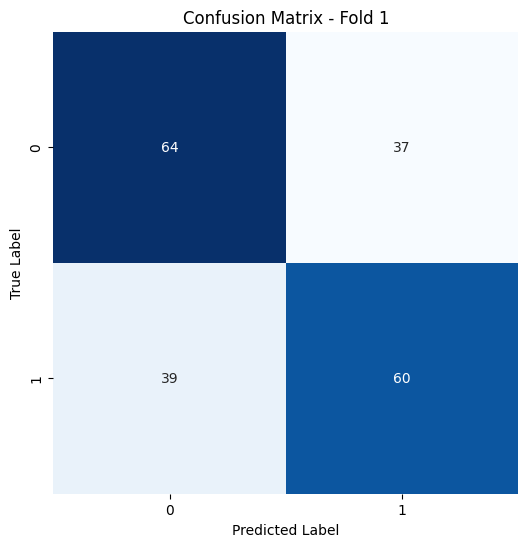


======== FOLD 2/5 ========


Map:   0%|          | 0/800 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

[I 2026-10-03 03:37:21,278] A new study created in memory with name: fold_1_hp_tuning


Optimizing hyperparameters for Fold 2...


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Auc Roc
0.255369,0.440138,7,0.889639


AUC-ROC do fold 2 com melhores HPs: 0.8896


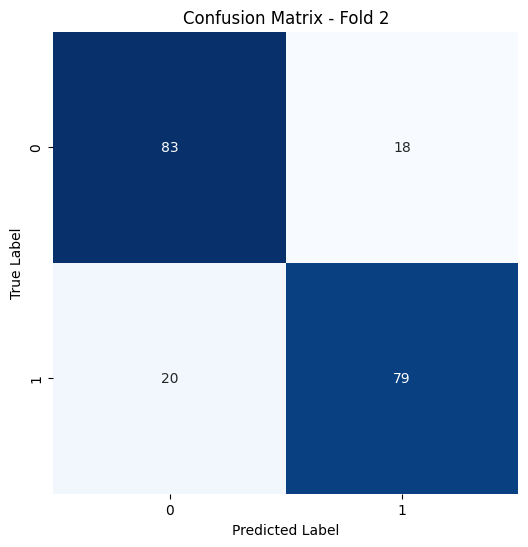


======== FOLD 3/5 ========


Map:   0%|          | 0/800 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

[I 2026-10-03 03:39:34,178] A new study created in memory with name: fold_2_hp_tuning


Optimizing hyperparameters for Fold 3...


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Auc Roc
0.479991,0.641134,3,0.691669


AUC-ROC do fold 3 com melhores HPs: 0.6917


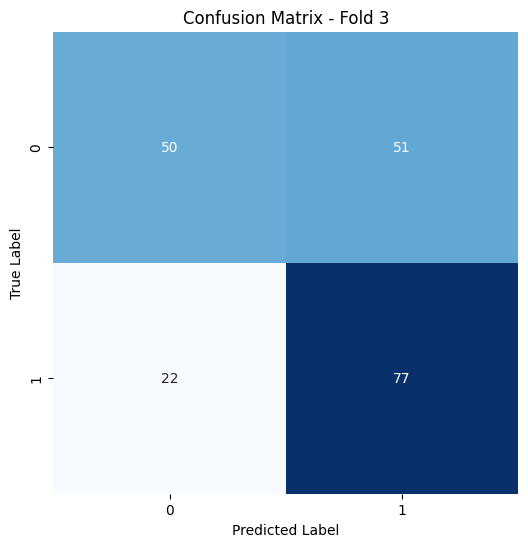


======== FOLD 4/5 ========


Map:   0%|          | 0/800 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

[I 2026-10-03 03:41:11,094] A new study created in memory with name: fold_3_hp_tuning


Optimizing hyperparameters for Fold 4...


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Auc Roc
0.248809,0.624359,7,0.783313


AUC-ROC do fold 4 com melhores HPs: 0.7833


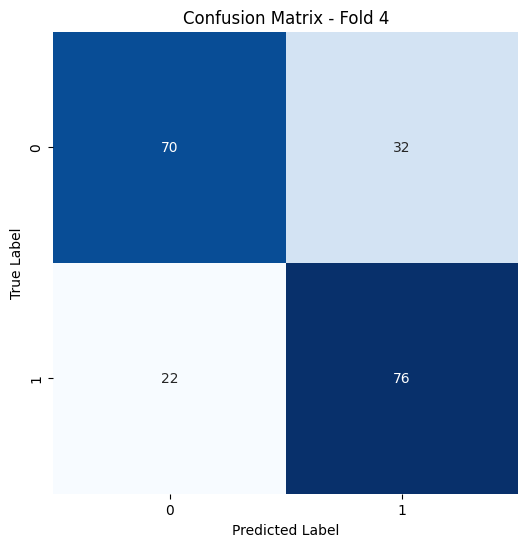


======== FOLD 5/5 ========


Map:   0%|          | 0/800 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

[I 2026-10-03 03:43:15,728] A new study created in memory with name: fold_4_hp_tuning


Optimizing hyperparameters for Fold 5...


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Auc Roc
0.591217,0.625554,6,0.708683


AUC-ROC do fold 5 com melhores HPs: 0.7087


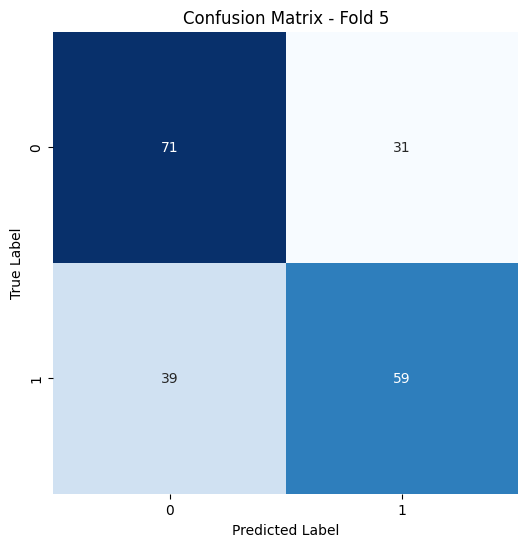


======= RESULTADOS FINAIS ======
AUC-ROC por fold: [0.7111711171117112, 0.8896389638963896, 0.6916691669166918, 0.7833133253301321, 0.7086834733893558]
Média: 0.756895209328856
Desvio padrão: 0.07346879872419038

======= MATRIZ DE CONFUSÃO AGREGADA ======


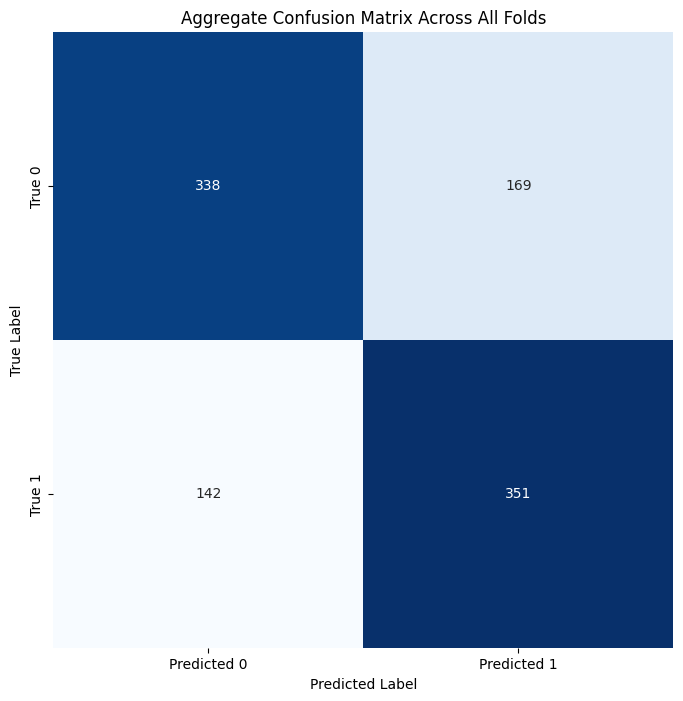

In [ ]:
import os
import shutil # Added for directory deletion
from tokenizers import ByteLevelBPETokenizer
from transformers import(
    RobertaTokenizerFast,
    RobertaForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorForTokenClassification,
    EarlyStoppingCallback # Added EarlyStoppingCallback
)
import numpy as np
from sklearn.model_selection import StratifiedKFold # Changed from KFold
from sklearn.metrics import confusion_matrix # Re-import here to be explicit if moved
import torch
import matplotlib.pyplot as plt # Added for plotting
import seaborn as sns # Added for plotting
import optuna # Added Optuna

VOCAB_SIZE = 5026
k = 5
kf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42) # Changed to StratifiedKFold

encoded = load_dataset("Italo002/medical-abstracts-binary-classification")
#encoded = sliced_dataset

# 🔥 limitar dataset (as per user's latest context)
small_dataset = encoded['train'].select(range(min(1000, len(encoded['train']))))
#small_dataset = encoded.select(range(min(5000, len(encoded))))

# Extract labels for StratifiedKFold
y_labels = np.array(small_dataset["label"]) # Use original 'label' column for stratification

X = np.arange(len(small_dataset))
results = []

# Initialize lists to store true labels and predictions for aggregate confusion matrix
all_y_true = []
all_y_pred = []

# Define model_init for Optuna
def model_init():
    return RobertaForSequenceClassification.from_pretrained(
        "distilroberta-base",
        num_labels=2
    )

for fold, (train_idx, test_idx) in enumerate(kf.split(X, y_labels)): # Added y_labels for stratification
    print(f"\n======== FOLD {fold+1}/{k} ========")

    # Get raw splits for current fold to train tokenizer and then re-tokenize
    train_split_raw = small_dataset.select(train_idx)
    eval_split_raw = small_dataset.select(test_idx)

    # 1. Create corpus.txt for the current fold's tokenizer training
    corpus_path = f"corpus_fold_{fold}.txt"
    with open(corpus_path, "w", encoding="utf-8") as f:
        for t in train_split_raw["medical_abstract"]:
            f.write(t + "\n")


    # 2. Train a new ByteLevelBPETokenizer for this fold
    bpe_tokenizer = ByteLevelBPETokenizer()
    bpe_tokenizer.train(
        files=[corpus_path], # Use the corpus from the current fold
        vocab_size=VOCAB_SIZE, # Use the global VOCAB_SIZE from a previous cell
        min_frequency=2,
        special_tokens=["<s>", "<pad>", "</s>", "<unk>", "<mask>"]
    )

    # 3. Save the trained tokenizer to a fold-specific directory
    tokenizer_dir = f"tokenizer_fold_{fold}"
    os.makedirs(tokenizer_dir, exist_ok=True)
    bpe_tokenizer.save(f"{tokenizer_dir}/tokenizer.json")

    # 4. Load the RobertaTokenizerFast from the newly saved tokenizer
    current_fold_tokenizer = RobertaTokenizerFast.from_pretrained(tokenizer_dir)

    # 5. Re-tokenize the train and eval splits using the current fold's tokenizer
    def tokenize_function(batch):
        return current_fold_tokenizer(
            batch["medical_abstract"],
            truncation=True,
            padding="max_length",
            max_length=128
        )

    train_split_encoded = train_split_raw.map(tokenize_function, batched=True)
    eval_split_encoded = eval_split_raw.map(tokenize_function, batched=True)

    # Remove unnecessary columns and rename 'label' to 'labels' for the Trainer
    # train_split_encoded = train_split_encoded.remove_columns(["text"])
    # eval_split_encoded = eval_split_encoded.remove_columns(["text"])
    train_split_encoded = train_split_encoded.rename_column("label", "labels")
    eval_split_encoded = eval_split_encoded.rename_column("label", "labels")

    # --- Optuna Hyperparameter Optimization ---
    def objective(trial):
        learning_rate = trial.suggest_loguniform("learning_rate", 1e-6, 1e-4)
        num_train_epochs = trial.suggest_int("num_train_epochs", 3, 7) # Suggest between 3 and 7 epochs

        # Model loading
        model = model_init()
        # Important: resize embeddings based on the current_fold_tokenizer
        model.resize_token_embeddings(len(current_fold_tokenizer))

        training_args = TrainingArguments(
            output_dir=f"./results_fold_{fold}_optuna_trial_{trial.number}", # Unique output dir for each trial
            learning_rate=learning_rate,
            per_device_train_batch_size=8,
            per_device_eval_batch_size=8,
            num_train_epochs=num_train_epochs, # Use suggested num_train_epochs
            weight_decay=0.01,
            eval_strategy="epoch",
            save_strategy="epoch",
            logging_strategy="steps",
            logging_steps=50,
            load_best_model_at_end=True,
            metric_for_best_model="eval_loss", # Optimize for low validation loss
            greater_is_better=False, # Minimize validation loss
            report_to="none" # Disable reporting to reduce overhead/logging
        )

        early_stopping_callback = EarlyStoppingCallback(early_stopping_patience=4, early_stopping_threshold=0.001)

        trainer = Trainer(
            model=model,
            args=training_args,
            train_dataset=train_split_encoded,
            eval_dataset=eval_split_encoded,
            compute_metrics=compute_auc_roc,
            callbacks=[early_stopping_callback]
        )

        trainer.train()
        metrics = trainer.evaluate()

        return metrics.get("eval_loss", float('inf')) # Return eval_loss for Optuna to minimize

    # Create an Optuna study and optimize
    print(f"Optimizing hyperparameters for Fold {fold+1}...")
    # Set OPTUNA_LOGGING_VERBOSITY to ERROR to suppress excessive output during trials
    os.environ["OPTUNA_LOGGING_VERBOSITY"] = "ERROR"
    study = optuna.create_study(direction="minimize", study_name=f"fold_{fold}_hp_tuning") # Changed to minimize
    study.optimize(objective, n_trials=4, show_progress_bar=True) # Start with 5 trials per fold

    print(f"Best trial for Fold {fold+1}:")
    print(f"  Value (Eval Loss): {study.best_value:.4f}") # Changed output label
    print(f"  Params: {study.best_trial.params}")

    # Clean up Optuna trial directories
    for trial in study.trials:
        trial_output_dir = f"./results_fold_{fold}_optuna_trial_{trial.number}"
        if os.path.exists(trial_output_dir):
            shutil.rmtree(trial_output_dir)

    # Re-initialize model and trainer with the best hyperparameters found by Optuna
    best_learning_rate = study.best_trial.params["learning_rate"]
    best_num_epochs = study.best_trial.params["num_train_epochs"]

    model = model_init()
    model.resize_token_embeddings(len(current_fold_tokenizer))

    training_args = TrainingArguments(
        output_dir=f"./results_fold_{fold}_final", # Final model directory
        learning_rate=best_learning_rate,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        num_train_epochs=best_num_epochs,
        weight_decay=0.01,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="steps",
        logging_steps=50,
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss", # Consistent with Optuna, minimize loss
        greater_is_better=False # Consistent with Optuna, minimize loss
    )

    early_stopping_callback = EarlyStoppingCallback(early_stopping_patience=4, early_stopping_threshold=0.001)

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_split_encoded,
        eval_dataset=eval_split_encoded,
        compute_metrics=compute_auc_roc,
        callbacks=[early_stopping_callback]
    )

    # Train the final model with best hyperparameters
    trainer.train()
    metrics = trainer.evaluate()

    print(f"AUC-ROC do fold {fold+1} com melhores HPs: {metrics['eval_auc_roc']:.4f}")
    results.append(metrics["eval_auc_roc"])

    # Generate predictions for the confusion matrix for the current fold
    predictions = trainer.predict(eval_split_encoded)
    y_pred_fold = np.argmax(predictions.predictions, axis=1)
    y_true_fold = predictions.label_ids

    # Append current fold's predictions and true labels to the aggregate lists
    all_y_true.extend(y_true_fold)
    all_y_pred.extend(y_pred_fold)

    # Compute and display confusion matrix for the current fold
    cm_fold = confusion_matrix(y_true_fold, y_pred_fold)
    plt.figure(figsize=(6, 6))
    sns.heatmap(cm_fold, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title(f'Confusion Matrix - Fold {fold+1}')
    plt.show()

    # Clean up corpus file and tokenizer directory for the current fold
    if os.path.exists(corpus_path):
        os.remove(corpus_path)
    if os.path.exists(tokenizer_dir):
        shutil.rmtree(tokenizer_dir)

# Reset Optuna logging verbosity
del os.environ["OPTUNA_LOGGING_VERBOSITY"]

# =======================================================
# 6. Resultados finais
# =======================================================
print("\n======= RESULTADOS FINAIS ======")
print("AUC-ROC por fold:", results)
print("Média:", np.mean(results))
print("Desvio padrão:", np.std(results))

# Compute and display the aggregate confusion matrix
print("\n======= MATRIZ DE CONFUSÃO AGREGADA ======")
aggregate_cm = confusion_matrix(all_y_true, all_y_pred)

plt.figure(figsize=(8, 8))
sns.heatmap(aggregate_cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['True 0', 'True 1'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Aggregate Confusion Matrix Across All Folds')
plt.show()

# **Treinamento com Vocabulário original**

In [ ]:
ds = load_dataset("stanfordnlp/imdb")
ds = ds["train"]

negative_results = ds.select(range(2500))
positive_results = ds.select(range(22500,25000))

sliced_dataset = concatenate_datasets([positive_results, negative_results])
sliced_dataset = sliced_dataset.shuffle(seed=42)

for i in range(10):
    print(sliced_dataset[4599+i]["label"])

tokenizer = RobertaTokenizerFast.from_pretrained("distilroberta-base")

def tokenize(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

encoded = sliced_dataset.map(tokenize, batched=True)

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

In [ ]:
# =======================================================
# 2. Tokenizer do RoBERTa
# =======================================================
#sliced_dataset = load_dataset("csv",data_files = "/content/sliced_dataset.csv")
sliced_dataset = load_dataset("Italo002/medical-abstracts-binary-classification")
tokenizer = RobertaTokenizerFast.from_pretrained("distilroberta-base")

def tokenize(batch):
    return tokenizer(
        batch["medical_abstract"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

encoded = sliced_dataset.map(tokenize, batched=True)

# remover colunas não usadas
encoded = encoded.remove_columns(["condition_label"])

In [ ]:
import os
import shutil
from transformers import (
    RobertaTokenizerFast,
    RobertaForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

k = 5
kf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

# 🔥 limitar dataset conforme os experimentos anteriores
small_dataset = encoded['train'].select(range(min(1000, len(encoded['train']))))
#small_dataset = encoded.select(range(min(1000, len(encoded))))

# Extrair rótulos para o StratifiedKFold
y_labels = np.array(small_dataset["label"])

X = np.arange(len(small_dataset))
results = []

# Listas para acumular as predições e rótulos reais de todos os folds
all_y_true = []
all_y_pred = []

def model_init():
    return RobertaForSequenceClassification.from_pretrained(
        "distilroberta-base",
        num_labels=2
    )

for fold, (train_idx, test_idx) in enumerate(kf.split(X, y_labels)):
    print(f"\n======== FOLD {fold+1}/{k} ========")

    train_split_encoded = small_dataset.select(train_idx)
    eval_split_encoded = small_dataset.select(test_idx)

    # Ajustar nomes de coluna para o Hugging Face Trainer
    train_split_encoded = train_split_encoded.rename_column("label", "labels")
    eval_split_encoded = eval_split_encoded.rename_column("label", "labels")

    # --- Optuna Hyperparameter Optimization ---
    def objective(trial):
        learning_rate = trial.suggest_loguniform("learning_rate", 1e-6, 1e-4)
        num_train_epochs = trial.suggest_int("num_train_epochs", 3, 7)

        model = model_init()
        model.resize_token_embeddings(len(tokenizer))

        training_args = TrainingArguments(
            output_dir=f"./results_original_fold_{fold}_optuna_trial_{trial.number}",
            learning_rate=learning_rate,
            per_device_train_batch_size=8,
            per_device_eval_batch_size=8,
            num_train_epochs=num_train_epochs,
            weight_decay=0.01,
            eval_strategy="epoch",
            save_strategy="epoch",
            logging_strategy="steps",
            logging_steps=50,
            load_best_model_at_end=True,
            metric_for_best_model="eval_loss",
            greater_is_better=False,
            report_to="none"
        )

        early_stopping_callback = EarlyStoppingCallback(early_stopping_patience=4, early_stopping_threshold=0.001)

        trainer = Trainer(
            model=model,
            args=training_args,
            train_dataset=train_split_encoded,
            eval_dataset=eval_split_encoded,
            compute_metrics=compute_auc_roc,
            callbacks=[early_stopping_callback]
        )

        trainer.train()
        metrics = trainer.evaluate()

        return metrics.get("eval_loss", float('inf'))

    print(f"Optimizando hiperparâmetros para Fold {fold+1}...")
    os.environ["OPTUNA_LOGGING_VERBOSITY"] = "ERROR"
    study = optuna.create_study(direction="minimize", study_name=f"original_fold_{fold}_hp_tuning")
    study.optimize(objective, n_trials=4, show_progress_bar=True)

    print(f"Best trial para Fold {fold+1}:")
    print(f"  Value (Eval Loss): {study.best_value:.4f}")
    print(f"  Params: {study.best_trial.params}")

    # Limpar diretórios temporários do Optuna
    for trial in study.trials:
        trial_output_dir = f"./results_original_fold_{fold}_optuna_trial_{trial.number}"
        if os.path.exists(trial_output_dir):
            shutil.rmtree(trial_output_dir)

    # Treinar modelo final com os melhores hiperparâmetros
    best_learning_rate = study.best_trial.params["learning_rate"]
    best_num_epochs = study.best_trial.params["num_train_epochs"]

    model = model_init()
    model.resize_token_embeddings(len(tokenizer))

    training_args = TrainingArguments(
        output_dir=f"./results_original_fold_{fold}_final",
        learning_rate=best_learning_rate,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        num_train_epochs=best_num_epochs,
        weight_decay=0.01,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="steps",
        logging_steps=50,
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False
    )

    early_stopping_callback = EarlyStoppingCallback(early_stopping_patience=4, early_stopping_threshold=0.001)

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_split_encoded,
        eval_dataset=eval_split_encoded,
        compute_metrics=compute_auc_roc,
        callbacks=[early_stopping_callback]
    )

    trainer.train()
    metrics = trainer.evaluate()

    print(f"AUC-ROC do fold {fold+1} com melhores HPs: {metrics['eval_auc_roc']:.4f}")
    results.append(metrics["eval_auc_roc"])

    # Previsões para a matriz de confusão
    predictions = trainer.predict(eval_split_encoded)
    y_pred_fold = np.argmax(predictions.predictions, axis=1)
    y_true_fold = predictions.label_ids

    all_y_true.extend(y_true_fold)
    all_y_pred.extend(y_pred_fold)

    # Matriz de confusão por fold
    cm_fold = confusion_matrix(y_true_fold, y_pred_fold)
    plt.figure(figsize=(6, 6))
    sns.heatmap(cm_fold, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title(f'Confusion Matrix - Fold {fold+1} (Vocab Original)')
    plt.show()

    # Limpar diretório de resultados final do fold
    fold_output_dir = f"./results_original_fold_{fold}_final"
    if os.path.exists(fold_output_dir):
        shutil.rmtree(fold_output_dir)

# Resetar verbosidade do Optuna
if "OPTUNA_LOGGING_VERBOSITY" in os.environ:
    del os.environ["OPTUNA_LOGGING_VERBOSITY"]

# =======================================================
# 6. Resultados finais
# =======================================================
print("\n======= RESULTADOS FINAIS (VOCAB ORIGINAL) ======")
print("AUC-ROC por fold:", results)
print("Média:", np.mean(results))
print("Desvio padrão:", np.std(results))

# Mostrar matriz de confusão agregada
print("\n======= MATRIZ DE CONFUSÃO AGREGADA ======")
aggregate_cm = confusion_matrix(all_y_true, all_y_pred)

plt.figure(figsize=(8, 8))
sns.heatmap(aggregate_cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['True 0', 'True 1'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Aggregate Confusion Matrix Across All Folds (Vocab Original)')
plt.show()

### Visualizing AUC-ROC Progression Across Dataset and Vocabulary Sizes

To effectively visualize the AUC-ROC progression with different dataset sizes (5000, 2500, 1000) and two vocabulary types (custom and original `distilroberta`), consider the following graph styles:

1.  **Grouped Bar Chart**: Ideal for comparing the average AUC-ROC score across all combinations of dataset size and vocabulary type. You can have dataset size on the x-axis, with bars grouped by vocabulary type (or vice-versa). This clearly shows which configurations perform best on average.

2.  **Box Plot / Violin Plot**: These are excellent for showing the distribution of AUC-ROC scores across the five folds for each combination. A box plot will display the median, quartiles, and potential outliers, giving you a sense of the stability and spread of the results for each configuration. A violin plot offers a richer view of the distribution shape.

3.  **Line Plot (with error bars)**: If you want to show the AUC-ROC for each fold, a line plot could track the score across folds for each configuration. However, with only 5 folds, box plots are generally more informative for showing variability. If you average the folds, error bars (e.g., standard deviation) can be added to a bar chart to show variability around the mean.

Let's generate some example code to create these visualizations with dummy data that simulates your experiment results.

,Dataset Size,Vocabulary Type,Fold,AUC-ROC
0,5000,Custom,1,0.8946
1,5000,Custom,2,0.8953
2,5000,Custom,3,0.8834
3,5000,Custom,4,0.8964
4,5000,Custom,5,0.8932


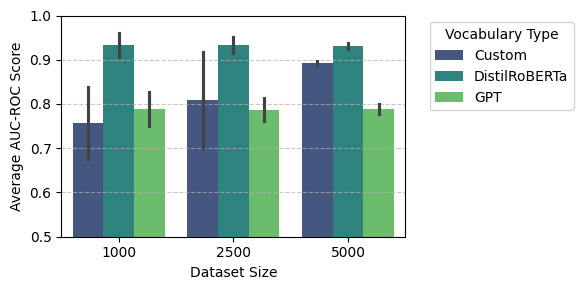

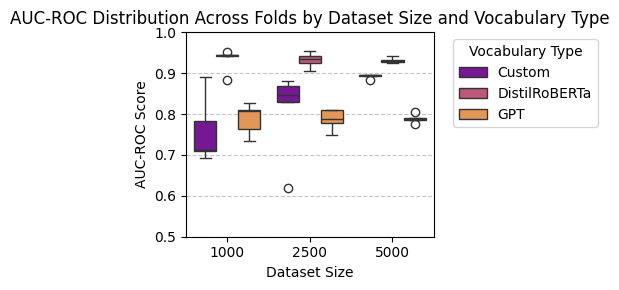

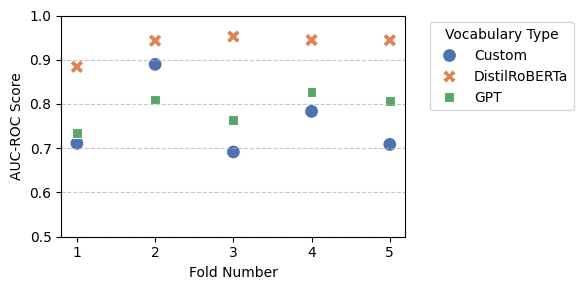

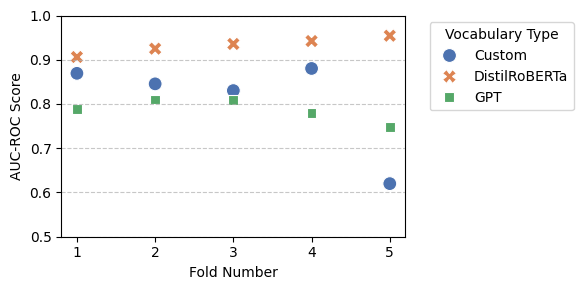

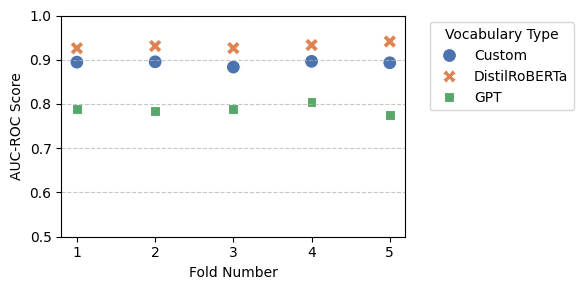

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# --- Create Dummy Data to Simulate Results ---
# Replace this with your actual results data structure
data_points = []
dataset_sizes = [5000, 2500, 1000]
vocabulary_types = ['Custom', 'DistilRoBERTa','GPT']
num_folds = 5

auc_roc_original = [(0.9260, 0.9310, 0.9263, 0.9332, 0.9412),
                    (0.9062, 0.9250, 0.9357, 0.9423, 0.9543),
                    (0.8840, 0.9430, 0.9524, 0.9445, 0.9440)]

auc_roc_custom = [(0.8946, 0.8953, 0.8834, 0.8964, 0.8932),
                  (0.8693, 0.8455, 0.8303, 0.8803, 0.6200),
                  (0.7111, 0.8896, 0.6916, 0.7833, 0.7086)]

auc_roc_gpt = [(0.7896, 0.7847, 0.7892, 0.8053, 0.7758),
               (0.7880, 0.8103, 0.8099, 0.7794, 0.7483),
               (0.7347, 0.8100, 0.7632, 0.8275, 0.8068)]

# Simulate AUC-ROC scores for each combination and fold
for ds_size in dataset_sizes:
    for vocab_type in vocabulary_types:
        for fold in range(1, num_folds + 1):
            # Simulate AUC-ROC scores (adjust these ranges for realistic values)
            if ds_size == 5000 and vocab_type == 'Custom':
                auc = auc_roc_custom[0][fold-1]
            elif ds_size == 5000 and vocab_type == 'DistilRoBERTa':
                auc = auc_roc_original[0][fold-1]
            elif ds_size == 5000 and vocab_type == 'GPT':
                auc = auc_roc_gpt[0][fold-1]
            elif ds_size == 2500 and vocab_type == 'Custom':
                auc = auc_roc_custom[1][fold-1]
            elif ds_size == 2500 and vocab_type == 'DistilRoBERTa':
                auc = auc_roc_original[1][fold-1]
            elif ds_size == 2500 and vocab_type == 'GPT':
                auc = auc_roc_gpt[1][fold-1]
            elif ds_size == 1000 and vocab_type == 'Custom':
                auc = auc_roc_custom[2][fold-1]
            elif ds_size == 1000 and vocab_type == 'DistilRoBERTa':
                auc = auc_roc_original[2][fold-1]
            else: #ds_size == 1000 and vocab_type == 'GPT'
                auc = auc_roc_gpt[2][fold-1]

            data_points.append({
                'Dataset Size': ds_size,
                'Vocabulary Type': vocab_type,
                'Fold': fold,
                'AUC-ROC': auc
            })

results_df = pd.DataFrame(data_points)
display(results_df.head())

# --- Plot 1: Grouped Bar Chart for Average AUC-ROC ---
plt.figure(figsize=(6, 3))
sns.barplot(data=results_df, x='Dataset Size', y='AUC-ROC', hue='Vocabulary Type', palette='viridis', errorbar='sd')
#plt.title('Average AUC-ROC by Dataset Size and Vocabulary Type (with Standard Deviation)')
plt.xlabel('Dataset Size')
plt.ylabel('Average AUC-ROC Score')
plt.ylim(0.5, 1.0) # Assuming AUC-ROC values are between 0 and 1
plt.legend(title='Vocabulary Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# --- Plot 2: Box Plot for AUC-ROC Distribution Across Folds ---
plt.figure(figsize=(5, 3))
sns.boxplot(data=results_df, x='Dataset Size', y='AUC-ROC', hue='Vocabulary Type', palette='plasma')
plt.title('AUC-ROC Distribution Across Folds by Dataset Size and Vocabulary Type')
plt.xlabel('Dataset Size')
plt.ylabel('AUC-ROC Score')
plt.ylim(0.5, 1.0) # Assuming AUC-ROC values are between 0 and 1
plt.legend(title='Vocabulary Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()



# --- Dispersion Graphs for each Dataset Size ---
for current_ds_size in sorted(results_df['Dataset Size'].unique()):
    plt.figure(figsize=(6, 3))
    sns.scatterplot(
        data=results_df[results_df['Dataset Size'] == current_ds_size],
        x='Fold',
        y='AUC-ROC',
        hue='Vocabulary Type',
        style='Vocabulary Type',
        s=100,
        palette='deep'
    )
    #plt.title(f'Individual AUC-ROC Scores per Fold (Dataset Size: {current_ds_size})')
    plt.xlabel('Fold Number')
    plt.ylabel('AUC-ROC Score')
    plt.ylim(0.5, 1.0)
    plt.xticks(range(1, num_folds + 1))
    plt.legend(title='Vocabulary Type', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()